### Install Dependencies

In [1]:
!pip install -q datasets sentence-transformers transformers accelerate scikit-learn pandas matplotlib seaborn

### Loading and preparing the dataset

In [2]:
import pandas as pd
from datasets import load_dataset

# Load the Banking77 dataset
dataset = load_dataset("PolyAI/banking77")
label_names = dataset["train"].features["label"].names

print(f"Total intents available: {len(label_names)}")
print(f"Full Train size: {len(dataset['train'])} | Full Test size: {len(dataset['test'])}")

# Select 10 closely related, easily confused customer support intents
selected_intents = [
    "card_arrival",
    "card_not_working",
    "declined_card_payment",
    "pending_card_payment",
    "reverted_card_payment?",
    "lost_or_stolen_card",
    "refund_not_showing_up",
    "request_refund",
    "transaction_charged_twice",
    "transfer_not_received_by_recipient"
]

# Handle exact casing in Banking77 label names (e.g., 'Refund_not_showing_up')
intent_to_id = {name.lower(): idx for idx, name in enumerate(label_names)}
selected_ids = [intent_to_id[intent.lower()] for intent in selected_intents]
clean_names = [label_names[i] for i in selected_ids]

# Filter train and test splits to our 10 classes
train_ds = dataset["train"].filter(lambda x: x["label"] in selected_ids)
test_ds = dataset["test"].filter(lambda x: x["label"] in selected_ids)

# Map original 0-76 IDs to clean 0-9 IDs
old_to_new_id = {old_id: new_id for new_id, old_id in enumerate(selected_ids)}

train_df = pd.DataFrame({
    "text": train_ds["text"],
    "label": [old_to_new_id[l] for l in train_ds["label"]],
    "intent": [clean_names[old_to_new_id[l]] for l in train_ds["label"]]
})

test_df = pd.DataFrame({
    "text": test_ds["text"],
    "label": [old_to_new_id[l] for l in test_ds["label"]],
    "intent": [clean_names[old_to_new_id[l]] for l in test_ds["label"]]
})

print(f"\nFiltered Train samples: {len(train_df)} | Filtered Test samples: {len(test_df)}")
print("\nClass distribution in Test set:")
print(test_df["intent"].value_counts())
print("\nSample tickets:")
display(train_df.sample(5, random_state=42))

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

... (2 outputs left out)

Filter:   0%|          | 0/10003 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3080 [00:00<?, ? examples/s]


Filtered Train samples: 1497 | Filtered Test samples: 400

Class distribution in Test set:
intent
card_arrival                          40
card_not_working                      40
lost_or_stolen_card                   40
transfer_not_received_by_recipient    40
pending_card_payment                  40
request_refund                        40
Refund_not_showing_up                 40
declined_card_payment                 40
transaction_charged_twice             40
reverted_card_payment?                40
Name: count, dtype: int64

Sample tickets:


,text,label,intent
1033,My card was rejected,2,declined_card_payment
1304,I went for a meal in Seattle and paid the bill...,8,transaction_charged_twice
1389,Why isn't my payment showing?,4,reverted_card_payment?
1488,"I noticed my card payment was cancelled, can y...",4,reverted_card_payment?
788,How can I get a refund for a purchase?,7,request_refund


## Model 1 — Zero-Shot NLI Representation Baseline

In [3]:
import time
import torch
from transformers import pipeline
from sklearn.metrics import classification_report, f1_score

# Clean snake_case and punctuation so the NLI hypothesis reads naturally
human_labels = [
    name.replace("_", " ").replace("?", "").strip().lower()
    for name in clean_names
]
human_to_id = {label: idx for idx, label in enumerate(human_labels)}

print("Candidate NLI labels:", human_labels)

# Load NLI zero-shot classifier on T4 GPU
device = 0 if torch.cuda.is_available() else -1
nli_pipe = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
    device=device
)

# Run batched inference and measure latency
start_time = time.time()
nli_outputs = nli_pipe(
    test_df["text"].tolist(),
    candidate_labels=human_labels,
    hypothesis_template="This customer support inquiry is about {}.",
    batch_size=32
)
nli_elapsed = time.time() - start_time

# Extract top predicted label IDs
nli_preds = [human_to_id[out["labels"][0]] for out in nli_outputs]
nli_f1 = f1_score(test_df["label"], nli_preds, average="macro")
nli_throughput = len(test_df) / nli_elapsed

# Store results for our final comparison table
benchmark_results = []
benchmark_results.append({
    "Approach": "1. Zero-Shot NLI (DeBERTa-v3)",
    "Labeled Data Needed": "0 shots",
    "Macro F1": round(nli_f1, 4),
    "Inference Time (s)": round(nli_elapsed, 2),
    "Tickets / Sec": round(nli_throughput, 1)
})

print(f"\n--- Model 1: Zero-Shot NLI Results ---")
print(f"Macro F1: {nli_f1:.4f} | Time: {nli_elapsed:.2f}s | Speed: {nli_throughput:.1f} tickets/sec\n")
print(classification_report(test_df["label"], nli_preds, target_names=clean_names, digits=3))

Candidate NLI labels: ['card arrival', 'card not working', 'declined card payment', 'pending card payment', 'reverted card payment', 'lost or stolen card', 'refund not showing up', 'request refund', 'transaction charged twice', 'transfer not received by recipient']


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]


--- Model 1: Zero-Shot NLI Results ---
Macro F1: 0.5407 | Time: 10.97s | Speed: 36.5 tickets/sec

                                    precision    recall  f1-score   support

                      card_arrival      0.842     0.400     0.542        40
                  card_not_working      0.698     0.925     0.796        40
             declined_card_payment      0.833     0.250     0.385        40
              pending_card_payment      0.357     0.250     0.294        40
            reverted_card_payment?      0.571     0.100     0.170        40
               lost_or_stolen_card      0.938     0.375     0.536        40
             Refund_not_showing_up      1.000     0.350     0.519        40
                    request_refund      0.921     0.875     0.897        40
         transaction_charged_twice      0.864     0.950     0.905        40
transfer_not_received_by_recipient      0.225     0.950     0.364        40

                          accuracy                          0.5

## Models 2 & 3 — Dense Embeddings (Zero-Shot Cosine Similarity & Supervised Classifier)

### Model 2 (Zero-Shot Label-Description Cosine Similarity)

In [4]:
import numpy as np
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression

# 1. Load the embedding model
embed_model = SentenceTransformer("BAAI/bge-small-en-v1.5")

# Encode train and test tickets once (normalize_embeddings=True makes dot product == cosine similarity)
X_train = embed_model.encode(train_df["text"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
X_test = embed_model.encode(test_df["text"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)

# ==========================================
# MODEL 2: Zero-Shot Embedding Similarity
# ==========================================
intent_descriptions = [
    "My new bank card has not arrived in the mail yet and I am tracking card delivery.",
    "My physical or virtual card is broken, malfunctioning, or completely failing to work at terminals.",
    "My card payment was declined or rejected at checkout when I tried to pay.",
    "A card payment is still showing as pending or processing and has not settled yet.",
    "A card payment was reverted, cancelled, or automatically reversed back to my account.",
    "I lost my card or someone stole it and I need to freeze or replace it immediately.",
    "I was promised a refund by a merchant but the refunded money is still not showing up in my balance.",
    "I want to request a refund and get my money back for a purchase or service.",
    "I was charged twice for the exact same transaction and see a duplicate charge on my statement.",
    "I sent a bank transfer to someone, but the recipient has not received the money yet."
]

start_time = time.time()
# Embed test tickets + class descriptions and compute cosine similarity matrix
test_vecs = embed_model.encode(test_df["text"].tolist(), batch_size=64, normalize_embeddings=True)
desc_vecs = embed_model.encode(intent_descriptions, normalize_embeddings=True)
similarity_matrix = np.matmul(test_vecs, desc_vecs.T)
zs_embed_preds = np.argmax(similarity_matrix, axis=1)
zs_embed_elapsed = time.time() - start_time

zs_embed_f1 = f1_score(test_df["label"], zs_embed_preds, average="macro")
zs_embed_throughput = len(test_df) / zs_embed_elapsed

benchmark_results.append({
    "Approach": "2. Zero-Shot Embedding Cosine Sim",
    "Labeled Data Needed": "0 shots (descriptions)",
    "Macro F1": round(zs_embed_f1, 4),
    "Inference Time (s)": round(zs_embed_elapsed, 2),
    "Tickets / Sec": round(zs_embed_throughput, 1)
})

print(f"--- Model 2: Zero-Shot Embedding Similarity Results ---")
print(f"Macro F1: {zs_embed_f1:.4f} | Time: {zs_embed_elapsed:.2f}s | Speed: {zs_embed_throughput:.1f} tickets/sec\n")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

--- Model 2: Zero-Shot Embedding Similarity Results ---
Macro F1: 0.8641 | Time: 0.22s | Speed: 1860.4 tickets/sec



### Model 3 (Frozen Embeddings + Supervised Logistic Regression)

In [5]:
# ==========================================
# MODEL 3: Supervised Logistic Regression on Frozen Embeddings
# ==========================================
clf = LogisticRegression(max_iter=1000, C=2.0, random_state=42)
clf.fit(X_train, train_df["label"])

# Measure full inference time (embedding encoding + classifier prediction)
start_time = time.time()
test_vecs_sup = embed_model.encode(test_df["text"].tolist(), batch_size=64, normalize_embeddings=True)
sup_preds = clf.predict(test_vecs_sup)
sup_probs = clf.predict_proba(test_vecs_sup)
sup_elapsed = time.time() - start_time

sup_f1 = f1_score(test_df["label"], sup_preds, average="macro")
sup_throughput = len(test_df) / sup_elapsed

benchmark_results.append({
    "Approach": "3. Frozen Embeddings + LogReg",
    "Labeled Data Needed": f"{len(train_df)} tickets",
    "Macro F1": round(sup_f1, 4),
    "Inference Time (s)": round(sup_elapsed, 2),
    "Tickets / Sec": round(sup_throughput, 1)
})

print(f"--- Model 3: Frozen Embeddings + Supervised Logistic Regression ---")
print(f"Macro F1: {sup_f1:.4f} | Time: {sup_elapsed:.2f}s | Speed: {sup_throughput:.1f} tickets/sec\n")
print(classification_report(test_df["label"], sup_preds, target_names=clean_names, digits=3))

--- Model 3: Frozen Embeddings + Supervised Logistic Regression ---
Macro F1: 0.9699 | Time: 0.26s | Speed: 1555.4 tickets/sec

                                    precision    recall  f1-score   support

                      card_arrival      0.976     1.000     0.988        40
                  card_not_working      1.000     1.000     1.000        40
             declined_card_payment      0.927     0.950     0.938        40
              pending_card_payment      0.975     0.975     0.975        40
            reverted_card_payment?      0.947     0.900     0.923        40
               lost_or_stolen_card      1.000     0.950     0.974        40
             Refund_not_showing_up      0.975     0.975     0.975        40
                    request_refund      1.000     0.950     0.974        40
         transaction_charged_twice      0.952     1.000     0.976        40
transfer_not_received_by_recipient      0.952     1.000     0.976        40

                          accuracy

## Model 4 — Generative Text-to-Text Classification

In [6]:
import difflib
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load instruction-tuned encoder-decoder model (matches Chapter 4's FLAN-T5 approach)
model_id = "google/flan-t5-base"
tokenizer = AutoTokenizer.from_pretrained(model_id)
flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)
flan_model.eval()

# Format clean category strings for the prompt
prompt_categories = [name.replace("?", "").strip() for name in clean_names]
cat_list_str = "\n".join([f"- {c}" for c in prompt_categories])

def build_prompt(ticket_text):
    return (
        f"Classify the customer support ticket into exactly one of the following categories:\n"
        f"{cat_list_str}\n\n"
        f"Ticket: \"{ticket_text}\"\n"
        f"Category:"
    )

# Helper to robustly map free-text model outputs back to valid class IDs (0-9)
norm_to_id = {c.lower().replace("_", " "): idx for idx, c in enumerate(prompt_categories)}

def parse_generated_label(raw_text):
    cleaned = raw_text.strip().lower().replace("_", " ").replace("?", "")
    if cleaned in norm_to_id:
        return norm_to_id[cleaned]
    # Fallback: fuzzy string match if the model slightly altered wording
    matches = difflib.get_close_matches(cleaned, norm_to_id.keys(), n=1, cutoff=0.4)
    if matches:
        return norm_to_id[matches[0]]
    return 0  # Fallback default if completely unparseable

# Run batched autoregressive generation
prompts = [build_prompt(t) for t in test_df["text"].tolist()]
flan_preds = []
raw_generations = []
batch_size = 32

start_time = time.time()
with torch.no_grad():
    for i in range(0, len(prompts), batch_size):
        batch_prompts = prompts[i : i + batch_size]
        inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True, max_length=256).to(flan_model.device)
        outputs = flan_model.generate(**inputs, max_new_tokens=16)
        decoded = tokenizer.batch_decode(outputs, skip_special_tokens=True)
        raw_generations.extend(decoded)
        flan_preds.extend([parse_generated_label(d) for d in decoded])

flan_elapsed = time.time() - start_time
flan_f1 = f1_score(test_df["label"], flan_preds, average="macro")
flan_throughput = len(test_df) / flan_elapsed

benchmark_results.append({
    "Approach": "4. Generative LLM (FLAN-T5-base)",
    "Labeled Data Needed": "0 shots (prompted)",
    "Macro F1": round(flan_f1, 4),
    "Inference Time (s)": round(flan_elapsed, 2),
    "Tickets / Sec": round(flan_throughput, 1)
})

print(f"--- Model 4: Generative Classification (FLAN-T5-base) ---")
print(f"Macro F1: {flan_f1:.4f} | Time: {flan_elapsed:.2f}s | Speed: {flan_throughput:.1f} tickets/sec\n")
print("Sample raw generations vs true labels:")
for idx in range(5):
    print(f"  Ticket: {test_df['text'].iloc[idx][:55]}... -> Generated: '{raw_generations[idx]}' | True: '{clean_names[test_df['label'].iloc[idx]]}'")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

--- Model 4: Generative Classification (FLAN-T5-base) ---
Macro F1: 0.6451 | Time: 9.64s | Speed: 41.5 tickets/sec

Sample raw generations vs true labels:
  Ticket: How do I locate my card?... -> Generated: 'card_arrival' | True: 'card_arrival'
  Ticket: I still have not received my new card, I ordered over a... -> Generated: 'card_not_working' | True: 'card_arrival'
  Ticket: I ordered a card but it has not arrived. Help please!... -> Generated: 'card_not_working' | True: 'card_arrival'
  Ticket: Is there a way to know when my card will arrive?... -> Generated: 'request_refund' | True: 'card_arrival'
  Ticket: My card has not arrived yet.... -> Generated: 'card_not_working' | True: 'card_arrival'


## Benchmarking

=== CHAPTER 4 TEXT CLASSIFICATION BENCHMARK ===


,Approach,Labeled Data Needed,Macro F1,Inference Time (s),Tickets / Sec
0,1. Zero-Shot NLI (DeBERTa-v3),0 shots,0.5407,10.97,36.5
1,2. Zero-Shot Embedding Cosine Sim,0 shots (descriptions),0.8641,0.22,1860.4
2,3. Frozen Embeddings + LogReg,1497 tickets,0.9699,0.26,1555.4
3,4. Generative LLM (FLAN-T5-base),0 shots (prompted),0.6451,9.64,41.5


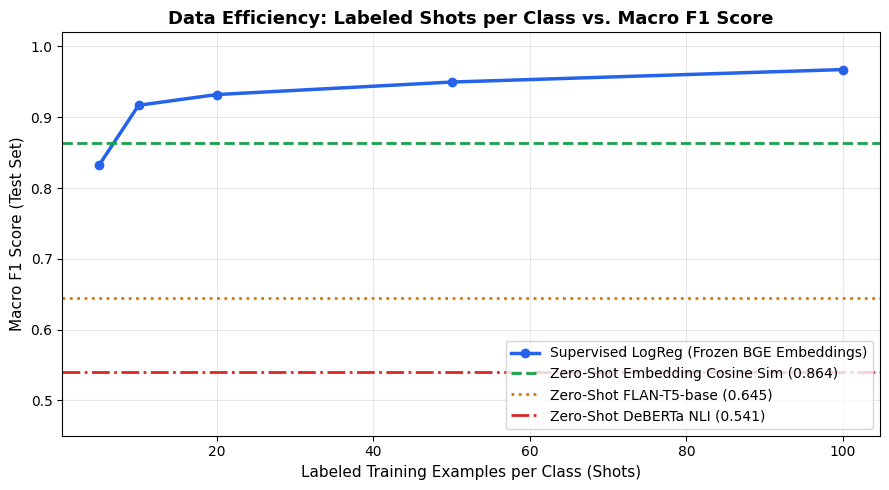


Saved 'ticket_router_clf.joblib' and 'router_config.json' successfully!


In [7]:
import json
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedShuffleSplit

# 1. Print Final Benchmark Comparison Table
results_df = pd.DataFrame(benchmark_results)
print("=== CHAPTER 4 TEXT CLASSIFICATION BENCHMARK ===")
display(results_df)

# 2. Low-Data Regime Experiment (How many labeled examples does LogReg need to beat Zero-Shot?)
shot_counts = [5, 10, 20, 50, 100]
learning_curve_f1 = []

for shots in shot_counts:
    # Sample 'shots' examples per class stratified
    sss = StratifiedShuffleSplit(n_splits=1, train_size=shots * len(clean_names), random_state=42)
    for sample_idx, _ in sss.split(X_train, train_df["label"]):
        sub_clf = LogisticRegression(max_iter=1000, C=2.0, random_state=42)
        sub_clf.fit(X_train[sample_idx], train_df["label"].iloc[sample_idx])
        preds = sub_clf.predict(X_test)
        learning_curve_f1.append(f1_score(test_df["label"], preds, average="macro"))

# Plot Learning Curve vs Zero-Shot Baselines
plt.figure(figsize=(9, 5))
plt.plot(shot_counts, learning_curve_f1, marker="o", linewidth=2.5, color="#2563eb", label="Supervised LogReg (Frozen BGE Embeddings)")
plt.axhline(zs_embed_f1, color="#16a34a", linestyle="--", linewidth=2, label=f"Zero-Shot Embedding Cosine Sim ({zs_embed_f1:.3f})")
plt.axhline(flan_f1, color="#d97706", linestyle=":", linewidth=2, label=f"Zero-Shot FLAN-T5-base ({flan_f1:.3f})")
plt.axhline(nli_f1, color="#dc2626", linestyle="-.", linewidth=2, label=f"Zero-Shot DeBERTa NLI ({nli_f1:.3f})")

plt.title("Data Efficiency: Labeled Shots per Class vs. Macro F1 Score", fontsize=13, fontweight="bold")
plt.xlabel("Labeled Training Examples per Class (Shots)", fontsize=11)
plt.ylabel("Macro F1 Score (Test Set)", fontsize=11)
plt.ylim(0.45, 1.02)
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 3. Save model artifacts for deployment
joblib.dump(clf, "ticket_router_clf.joblib")
config = {
    "embedding_model": "BAAI/bge-small-en-v1.5",
    "clean_names": clean_names,
    "intent_descriptions": intent_descriptions,
    "benchmark_summary": benchmark_results
}
with open("router_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved 'ticket_router_clf.joblib' and 'router_config.json' successfully!")


In [8]:
!pip install -q gradio

import gradio as gr
import numpy as np

# Precompute description embeddings for instant zero-shot comparison in the UI
desc_vecs = embed_model.encode(intent_descriptions, normalize_embeddings=True)

def route_ticket(ticket_text, confidence_threshold):
    if not ticket_text.strip():
        return "Please enter a customer support message.", {}, {}

    # 1. Embed incoming ticket
    vec = embed_model.encode([ticket_text], normalize_embeddings=True)

    # 2. Supervised Logistic Regression probabilities
    sup_probs = clf.predict_proba(vec)[0]
    top_sup_idx = int(np.argmax(sup_probs))
    top_sup_conf = float(sup_probs[top_sup_idx])
    top_sup_label = clean_names[top_sup_idx]

    # 3. Zero-Shot Cosine Similarity scores (normalized via softmax for display)
    cos_sims = np.matmul(vec, desc_vecs.T)[0]
    exp_sims = np.exp((cos_sims - np.max(cos_sims)) * 15)  # temperature-scaled softmax
    zs_probs = exp_sims / np.sum(exp_sims)

    # Routing decision logic
    if top_sup_conf >= confidence_threshold:
        status = f"AUTO-ROUTED -> Queue: `{top_sup_label}` (Confidence: {top_sup_conf:.1%})"
    else:
        status = f"ESCALATE TO HUMAN / LLM -> Top guess: `{top_sup_label}` ({top_sup_conf:.1%}) is below {confidence_threshold:.0%} threshold"

    sup_dict = {clean_names[i]: float(sup_probs[i]) for i in range(len(clean_names))}
    zs_dict = {clean_names[i]: float(zs_probs[i]) for i in range(len(clean_names))}

    return status, sup_dict, zs_dict

examples = [
    ["I tried paying at the grocery store twice and both transactions went through on my statement!", 0.65],
    ["My new card was supposed to arrive Tuesday, can you check where it is?", 0.65],
    ["The merchant cancelled my order last week, why is the charge still pending?", 0.65],
    ["Someone took my wallet on the subway, please freeze my account right now.", 0.65]
]

demo = gr.Interface(
    fn=route_ticket,
    inputs=[
        gr.Textbox(lines=3, placeholder="Type a customer banking support ticket...", label="Incoming Customer Ticket"),
        gr.Slider(minimum=0.30, maximum=0.95, value=0.65, step=0.05, label="Auto-Routing Confidence Threshold")
    ],
    outputs=[
        gr.Markdown(label="Routing Decision"),
        gr.Label(num_top_classes=4, label="Supervised Classifier (Frozen BGE + LogReg)"),
        gr.Label(num_top_classes=4, label="Zero-Shot Embedding Cosine Similarity")
    ],
    title="Multi-Paradigm Banking Ticket Triage Router",
    description="Built from Hands-On Large Language Models (Chapter 4). Compare Supervised Embedding Classification vs. Zero-Shot Label-Description Similarity in real time.",
    examples=examples
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c40d0a0c6d0aa315c1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_df["label"], sup_preds).tolist()

# Store test predictions & confidences so the Streamlit app can simulate threshold trade-offs
test_eval_records = [
    {
        "text": test_df["text"].iloc[i],
        "true_label": clean_names[test_df["label"].iloc[i]],
        "pred_label": clean_names[sup_preds[i]],
        "confidence": round(float(np.max(sup_probs[i])), 4)
    }
    for i in range(len(test_df))
]

config["confusion_matrix"] = cm
config["test_eval_records"] = test_eval_records

with open("router_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Updated router_config.json with confusion matrix and threshold simulation data!")

Updated router_config.json with confusion matrix and threshold simulation data!
